In [1]:
import os
for dirname, _, filenames in os.walk("/kaggle/input"):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/competitions/titanic/train.csv
/kaggle/input/competitions/titanic/test.csv
/kaggle/input/competitions/titanic/gender_submission.csv


# 1. Goal and data overview
Predict which Titanic passengers survived. Metric: accuracy. Baseline: gender rule (0.76555).

In [2]:
import pandas as pd

DATA = "/kaggle/input/competitions/titanic/"

train = pd.read_csv(DATA + "train.csv")
test = pd.read_csv(DATA + "test.csv")

print(train.shape, test.shape)

(891, 12) (418, 11)


In [3]:
test["Survived"] = (test["Sex"] == "female").astype(int)
test[["PassengerId", "Survived"]].to_csv("submission.csv", index=False)

# 2. Exploratory analysis
Key findings: sex, class, and title are the strongest signals; family size is non-linear.

In [4]:
print(train.info())
print()
print(train.isna().sum())
print()
print("Overall survival rate:", train["Survived"].mean().round(3))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int

In [5]:
for col in ["Sex", "Pclass", "Embarked"]:
    print(train.groupby(col)["Survived"].agg(["mean", "count"]).round(3))
    print()

         mean  count
Sex                 
female  0.742    314
male    0.189    577

         mean  count
Pclass              
1       0.630    216
2       0.473    184
3       0.242    491

           mean  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.337    644



In [6]:
for col in ["Sex", "Pclass", "Embarked"]:
    print(train.groupby(col)["Survived"].agg(["mean", "count"]).round(3))
    print()

         mean  count
Sex                 
female  0.742    314
male    0.189    577

         mean  count
Pclass              
1       0.630    216
2       0.473    184
3       0.242    491

           mean  count
Embarked              
C         0.554    168
Q         0.390     77
S         0.337    644



In [7]:
print(train.groupby("SibSp")["Survived"].agg(["mean", "count"]).round(3))
print()
print(train.groupby("Parch")["Survived"].agg(["mean", "count"]).round(3))
print()

train["AgeGroup"] = pd.cut(train["Age"], bins=[0, 5, 12, 18, 35, 60, 100])
print(train.groupby("AgeGroup", observed=True)["Survived"].agg(["mean", "count"]).round(3))

        mean  count
SibSp              
0      0.345    608
1      0.536    209
2      0.464     28
3      0.250     16
4      0.167     18
5      0.000      5
8      0.000      7

        mean  count
Parch              
0      0.344    678
1      0.551    118
2      0.500     80
3      0.600      5
4      0.000      4
5      0.200      5
6      0.000      1

            mean  count
AgeGroup               
(0, 5]     0.705     44
(5, 12]    0.360     25
(12, 18]   0.429     70
(18, 35]   0.383    358
(35, 60]   0.400    195
(60, 100]  0.227     22


In [8]:
# "Braund, Mr. Owen Harris" -> "Mr"
train["Title"] = train["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
train["FamilySize"] = train["SibSp"] + train["Parch"] + 1   # +1 counts the passenger

print(train["Title"].value_counts())
print()
print(train.groupby("Title")["Survived"].agg(["mean", "count"]).round(3))
print()
print(train.groupby("FamilySize")["Survived"].agg(["mean", "count"]).round(3))

Title
Mr              517
Miss            182
Mrs             125
Master           40
Dr                7
Rev               6
Col               2
Mlle              2
Major             2
Ms                1
Mme               1
Don               1
Lady              1
Sir               1
Capt              1
the Countess      1
Jonkheer          1
Name: count, dtype: int64

               mean  count
Title                     
Capt          0.000      1
Col           0.500      2
Don           0.000      1
Dr            0.429      7
Jonkheer      0.000      1
Lady          1.000      1
Major         0.500      2
Master        0.575     40
Miss          0.698    182
Mlle          1.000      2
Mme           1.000      1
Mr            0.157    517
Mrs           0.792    125
Ms            1.000      1
Rev           0.000      6
Sir           1.000      1
the Countess  1.000      1

             mean  count
FamilySize              
1           0.304    537
2           0.553    161
3           0

In [9]:
print(pd.crosstab(train["Embarked"], train["Pclass"], normalize="index").round(2))

Pclass       1     2     3
Embarked                  
C         0.51  0.10  0.39
Q         0.03  0.04  0.94
S         0.20  0.25  0.55


# 3. Cleaning and feature engineering
Titles from names, family groups, cabin flag; missing values filled using train-only statistics.

In [10]:
title_map = {"Mr": "Mr", "Mrs": "Mrs", "Miss": "Miss", "Master": "Master",
             "Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"}

def add_features(df):
    df = df.copy()
    title = df["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    df["Title"] = title.map(title_map).fillna("Rare")   # anything unlisted -> Rare
    df["FamilySize"] = df["SibSp"] + df["Parch"] + 1
    df["FamilyGroup"] = pd.cut(df["FamilySize"], bins=[0, 1, 4, 20],
                               labels=["Alone", "Small", "Large"])
    df["HasCabin"] = df["Cabin"].notna().astype(int)    # cabin known or not
    return df

train = add_features(train)
test = add_features(test)
print(train["Title"].value_counts())
print(test["Title"].value_counts())

Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64
Title
Mr        240
Miss       79
Mrs        72
Master     21
Rare        6
Name: count, dtype: int64


In [11]:
# Age: use the typical (median) age for each title, measured on train only
age_by_title = train.groupby("Title")["Age"].median()
print(age_by_title)

for df in (train, test):
    df["Age"] = df["Age"].fillna(df["Title"].map(age_by_title))
    df["Embarked"] = df["Embarked"].fillna(train["Embarked"].mode()[0])

# The one missing Fare in test: use the median fare of that passenger's class
fare_by_class = train.groupby("Pclass")["Fare"].median()
test["Fare"] = test["Fare"].fillna(test["Pclass"].map(fare_by_class))

cols = ["Age", "Embarked", "Fare", "Title", "FamilyGroup"]
print(train[cols].isna().sum())
print(test[cols].isna().sum())

Title
Master     3.5
Miss      21.0
Mr        30.0
Mrs       35.0
Rare      48.5
Name: Age, dtype: float64
Age            0
Embarked       0
Fare           0
Title          0
FamilyGroup    0
dtype: int64
Age            0
Embarked       0
Fare           0
Title          0
FamilyGroup    0
dtype: int64


# 4. Model comparison (cross-validation)
Logistic Regression, Random Forest, and Gradient Boosting compared on repeated 5-fold CV.

In [12]:
features = ["Pclass", "Sex", "Age", "Fare", "Embarked", "Title", "FamilyGroup", "HasCabin"]

X = pd.get_dummies(train[features])          # text columns -> 0/1 columns
y = train["Survived"]
X_test = pd.get_dummies(test[features]).reindex(columns=X.columns, fill_value=0)

print(X.shape, X_test.shape)
print(list(X.columns))

(891, 17) (418, 17)
['Pclass', 'Age', 'Fare', 'HasCabin', 'Sex_female', 'Sex_male', 'Embarked_C', 'Embarked_Q', 'Embarked_S', 'Title_Master', 'Title_Miss', 'Title_Mr', 'Title_Mrs', 'Title_Rare', 'FamilyGroup_Alone', 'FamilyGroup_Small', 'FamilyGroup_Large']


In [13]:
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=42)

models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=5,
                                            min_samples_leaf=3, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=150, max_depth=3,
                                                    learning_rate=0.05, random_state=42),
}

for name, model in models.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring="accuracy")
    print(f"{name:20s} mean = {scores.mean():.4f}   std = {scores.std():.4f}")

Logistic Regression  mean = 0.8264   std = 0.0181
Random Forest        mean = 0.8328   std = 0.0197
Gradient Boosting    mean = 0.8387   std = 0.0181


# 5. Final model and submission
Gradient Boosting on the engineered features. Leaderboard score: 0.77033.

In [14]:
final_model = GradientBoostingClassifier(n_estimators=150, max_depth=3,
                                         learning_rate=0.05, random_state=42)
final_model.fit(X, y)

preds = final_model.predict(X_test)

submission = pd.DataFrame({"PassengerId": test["PassengerId"], "Survived": preds})
submission.to_csv("submission.csv", index=False)

print(submission.shape)
print(submission["Survived"].value_counts())
print(submission.head())

(418, 2)
Survived
0    268
1    150
Name: count, dtype: int64
   PassengerId  Survived
0          892         0
1          893         0
2          894         0
3          895         0
4          896         1


In [15]:
importance = pd.Series(final_model.feature_importances_, index=X.columns)
print(importance.sort_values(ascending=False).round(3).head(10))

Title_Mr             0.462
Fare                 0.153
Pclass               0.106
Age                  0.071
FamilyGroup_Large    0.064
Title_Rare           0.054
HasCabin             0.029
Sex_male             0.020
Sex_female           0.011
Embarked_S           0.010
dtype: float64


# 6. Experiments and lessons learned
Ideas I tested and rejected, plus the full experiment log.

In [16]:
from sklearn.model_selection import RandomizedSearchCV

param_dist = {
    "n_estimators":     [100, 150, 200, 300],
    "max_depth":        [2, 3, 4],
    "learning_rate":    [0.01, 0.02, 0.05, 0.1],
    "min_samples_leaf": [1, 3, 5, 10],
    "subsample":        [0.7, 0.85, 1.0],
}

search = RandomizedSearchCV(GradientBoostingClassifier(random_state=42),
                            param_dist, n_iter=30, cv=cv,
                            scoring="accuracy", random_state=42, n_jobs=-1)
search.fit(X, y)

print("Best settings:", search.best_params_)
print("Search score (optimistic):", round(search.best_score_, 4))

# Fair re-check on fresh splits
cv2 = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=7)
tuned = GradientBoostingClassifier(random_state=42, **search.best_params_)
current = GradientBoostingClassifier(n_estimators=150, max_depth=3,
                                     learning_rate=0.05, random_state=42)

print("Tuned   on fresh splits:", round(cross_val_score(tuned, X, y, cv=cv2).mean(), 4))
print("Current on fresh splits:", round(cross_val_score(current, X, y, cv=cv2).mean(), 4))

Best settings: {'subsample': 1.0, 'n_estimators': 200, 'min_samples_leaf': 10, 'max_depth': 3, 'learning_rate': 0.1}
Search score (optimistic): 0.8373
Tuned   on fresh splits: 0.835
Current on fresh splits: 0.8316


In [17]:
from sklearn.ensemble import VotingClassifier

lr = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
rf = RandomForestClassifier(n_estimators=300, max_depth=5,
                            min_samples_leaf=3, random_state=42)
gb = GradientBoostingClassifier(n_estimators=150, max_depth=3,
                                learning_rate=0.05, random_state=42)

ensemble = VotingClassifier(
    estimators=[("lr", lr), ("rf", rf), ("gb", gb)],
    voting="soft"
)

for label, splits in [("original splits", cv), ("fresh splits   ", cv2)]:
    s_gb = cross_val_score(gb, X, y, cv=splits, scoring="accuracy")
    s_en = cross_val_score(ensemble, X, y, cv=splits, scoring="accuracy")
    print(f"{label}  GB alone: {s_gb.mean():.4f}   Ensemble: {s_en.mean():.4f}")

original splits  GB alone: 0.8387   Ensemble: 0.8305
fresh splits     GB alone: 0.8316   Ensemble: 0.8331


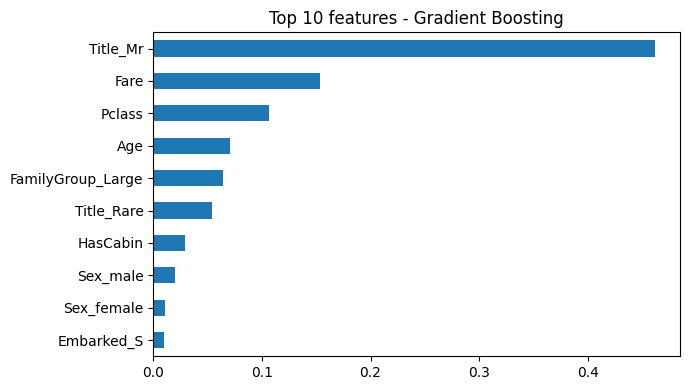

In [18]:
import matplotlib.pyplot as plt

imp = pd.Series(final_model.feature_importances_, index=X.columns).sort_values().tail(10)
imp.plot(kind="barh", figsize=(7, 4), title="Top 10 features - Gradient Boosting")
plt.tight_layout()
plt.savefig("feature_importance.png", dpi=150)
plt.show()

## Experiment log

| # | Experiment | CV accuracy | Leaderboard | Decision |
|---|-----------|-------------|-------------|----------|
| 1 | Gender rule baseline | 0.787 | 0.76555 | Baseline |
| 2 | Gradient Boosting + Title, FamilyGroup, HasCabin | 0.8387 | 0.77033 | **Final model** |
| 3 | + TicketCount / FarePerPerson | 0.8339-0.8373 | not submitted | Dropped (no gain) |
| 4 | Randomized hyperparameter search | 0.835 vs 0.8316 (fresh splits) | not submitted | Dropped (gain under noise) |
| 5 | Soft-voting ensemble (LR + RF + GB) | 0.8305 / 0.8331 | not submitted | Dropped (inconsistent) |

**Takeaway:** Features built from passenger names (title) and family size drove the
gain over the gender baseline. Later ideas were tested with repeated cross-validation
and rejected when they did not beat the noise level (about +/-0.018 between folds).